# **3 - Modelagem de Estados de Mortalidade (Estágio 1)**

Seguindo a metodologia de clusterização em múltiplos estágios de [Araújo (2026)](https://arxiv.org/abs/2609.17268), nosso primeiro objetivo é reduzir a complexidade das trajetórias demográficas identificando um conjunto discreto de **"estados de mortalidade"**. 

**Inovação Metodológica:** Embora a literatura base utilize o K-Means, os próprios autores apontam que ele tende a forçar clusters de tamanhos iguais e ignora a incerteza probabilística das curvas de mortalidade. Para garantir a melhor modelagem, testaremos três algoritmos distintos:
1. **K-Means:** Abordagem padrão baseada em distância centrada.
2. **Clusterização Hierárquica (Agglomerative):** Abordagem *bottom-up* que não assume formas esféricas para os clusters.
3. **Gaussian Mixture Models (GMM):** Abordagem probabilística sugerida como aprimoramento pela literatura para lidar com zonas de transição entre estados de mortalidade.

Avaliaremos a performance através do *Silhouette Score* (para medir a coesão e separação) iterando de $k=2$ a $k=10$.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Configuração visual
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 10.5,
    "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.labelsize": 10.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.alpha": 0.25, "legend.frameon": False
})

In [3]:
# 1. Carregamento e Filtro
df = pd.read_csv('../new_data/wpp2024_clean.csv')
df_hist = df[df['Ano'] <= 2023].copy()

# 2. Seleção das features de modelagem
features = [
    'Exp_Vida_Nascer', 
    'Mort_Infantil_Sub5', 
    'Mort_Adulta_15_60', 
    'Exp_Vida_15', 
    'Exp_Vida_65', 
    'Exp_Vida_80'
]

X = df_hist[features]

# 3. Padronização das variáveis (Média = 0, Desvio Padrão = 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Matriz de features pronta: {X_scaled.shape}")

Matriz de features pronta: (11914, 6)


## **3.1 Seleção de Algoritmos: Encontrando o $K$ Ideal**

Vamos rodar os três algoritmos (K-Means, GMM e Hierárquico) variando o número de perfis ($k$) de 2 a 10. A métrica de avaliação será o **Score de Silhueta**. Valores mais próximos de 1 indicam clusters perfeitamente separados, enquanto valores próximos a 0 indicam sobreposição.

In [4]:
k_range = range(2, 11)

# Dicionários para guardar os resultados
silhouettes = {
    'K-Means': [],
    'Hierárquico': [],
    'GMM': []
}

# Iterando sobre os k's
for k in k_range:
    # 1. K-Means
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_kmeans = kmeans.fit_predict(X_scaled)
    silhouettes['K-Means'].append(silhouette_score(X_scaled, labels_kmeans))
    
    # 2. Agglomerative (Hierárquico)
    hierarchical = AgglomerativeClustering(n_clusters=k)
    labels_hierarchical = hierarchical.fit_predict(X_scaled)
    silhouettes['Hierárquico'].append(silhouette_score(X_scaled, labels_hierarchical))
    
    # 3. Gaussian Mixture Models (GMM)
    gmm = GaussianMixture(n_components=k, random_state=42, n_init=5)
    labels_gmm = gmm.fit_predict(X_scaled)
    silhouettes['GMM'].append(silhouette_score(X_scaled, labels_gmm))

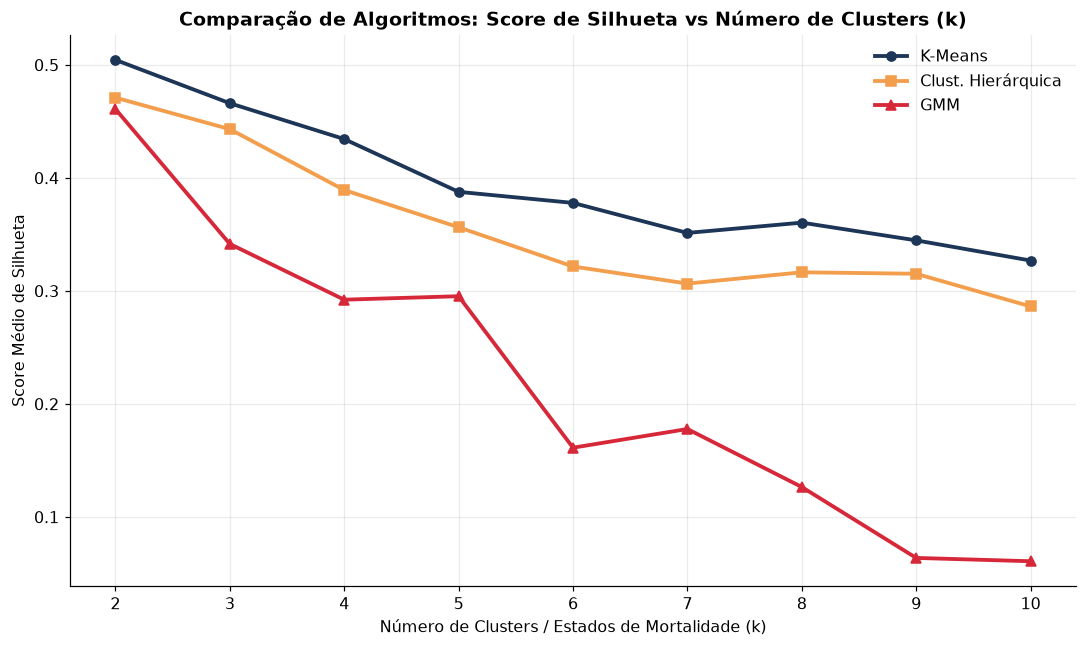

In [5]:
# Plotando a comparação
plt.figure(figsize=(10, 6))

plt.plot(k_range, silhouettes['K-Means'], marker='o', label='K-Means', linewidth=2.5, color='#1D3557')
plt.plot(k_range, silhouettes['Hierárquico'], marker='s', label='Clust. Hierárquica', linewidth=2.5, color='#F29E4C')
plt.plot(k_range, silhouettes['GMM'], marker='^', label='GMM', linewidth=2.5, color='#D62839')

plt.title('Comparação de Algoritmos: Score de Silhueta vs Número de Clusters (k)')
plt.xlabel('Número de Clusters / Estados de Mortalidade (k)')
plt.ylabel('Score Médio de Silhueta')
plt.xticks(k_range)
plt.legend()
plt.tight_layout()
plt.show()

### **3.2 - Melhorando os Hiperparâmetros (GMM e Hierárquico)**

Como o K-Means apresentou a melhor performance inicial, vamos investigar se ajustes finos nos hiperparâmetros dos outros algoritmos podem reverter esse cenário. 
* Para o **GMM**, testaremos o tipo de matriz de covariância (`full`, `tied`, `diag`, `spherical`) avaliando o Critério de Informação Bayesiano (BIC).
* Para o **Hierárquico**, testaremos diferentes métodos de ligação (`linkage`).

In [6]:
# 1. Tunagem do GMM usando BIC (Valores menores de BIC são melhores)
cov_types = ['full', 'tied', 'diag', 'spherical']
bic_scores = {cov: [] for cov in cov_types}

for cov in cov_types:
    for k in k_range:
        gmm = GaussianMixture(n_components=k, covariance_type=cov, random_state=42, n_init=5)
        gmm.fit(X_scaled)
        bic_scores[cov].append(gmm.bic(X_scaled))

In [7]:
# 2. Tunagem do Hierárquico usando Silhouette Score
linkages = ['ward', 'complete', 'average']
hier_scores = {link: [] for link in linkages}

for link in linkages:
    for k in k_range:
        hier = AgglomerativeClustering(n_clusters=k, linkage=link)
        labels = hier.fit_predict(X_scaled)
        hier_scores[link].append(silhouette_score(X_scaled, labels))

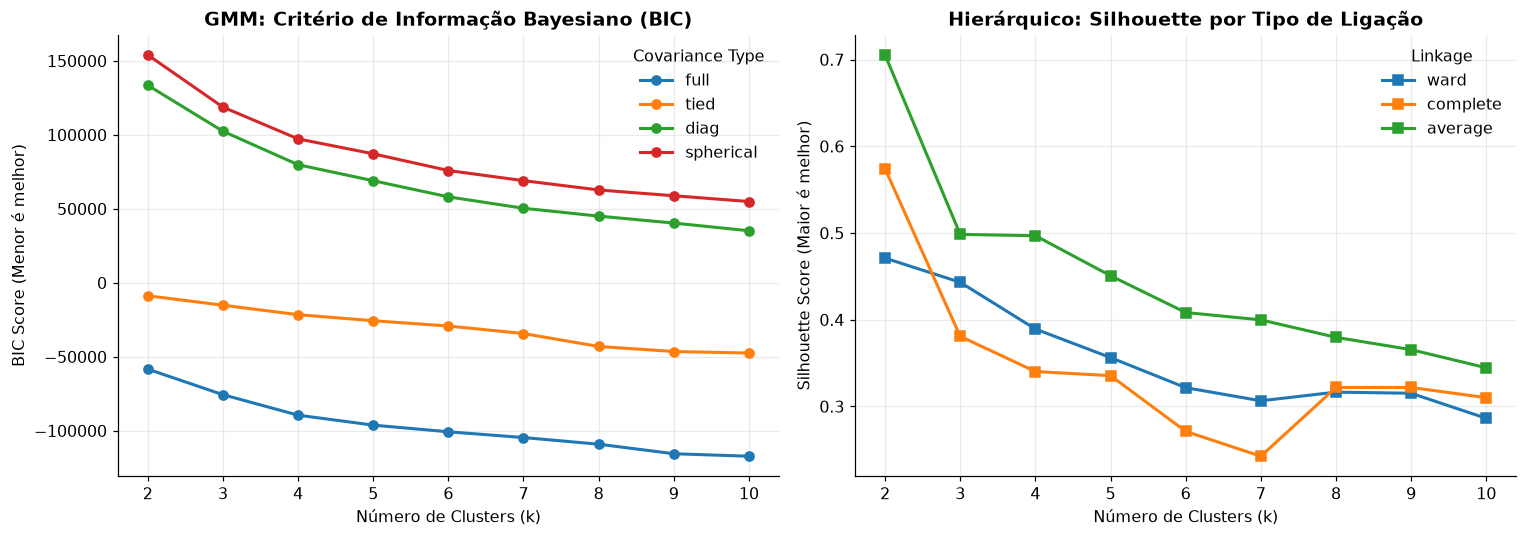

In [8]:
# Plotando as Tunagens
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico GMM (BIC)
for cov in cov_types:
    axes[0].plot(k_range, bic_scores[cov], marker='o', label=cov, linewidth=2)
axes[0].set_title('GMM: Critério de Informação Bayesiano (BIC)')
axes[0].set_xlabel('Número de Clusters (k)')
axes[0].set_ylabel('BIC Score (Menor é melhor)')
axes[0].legend(title='Covariance Type')
axes[0].set_xticks(k_range)

# Gráfico Hierárquico (Silhouette)
for link in linkages:
    axes[1].plot(k_range, hier_scores[link], marker='s', label=link, linewidth=2)
axes[1].set_title('Hierárquico: Silhouette por Tipo de Ligação')
axes[1].set_xlabel('Número de Clusters (k)')
axes[1].set_ylabel('Silhouette Score (Maior é melhor)')
axes[1].legend(title='Linkage')
axes[1].set_xticks(k_range)

plt.tight_layout()
plt.show()

## **3.3 - Diagrama de Silhueta para o K-Means**

Após validar que o K-Means com hiperparâmetros padrão é o modelo mais robusto para nossos dados demográficos, precisamos escolher o valor final de $K$.

A literatura rejeita $K=2$ por ser uma visão binária simplista. Vamos gerar os **Diagramas de Silhueta** para $K=3$ e $K=5$ (os valores adotados para fêmeas e machos no estudo base) para visualizar a densidade e o formato interno de cada estado de mortalidade.

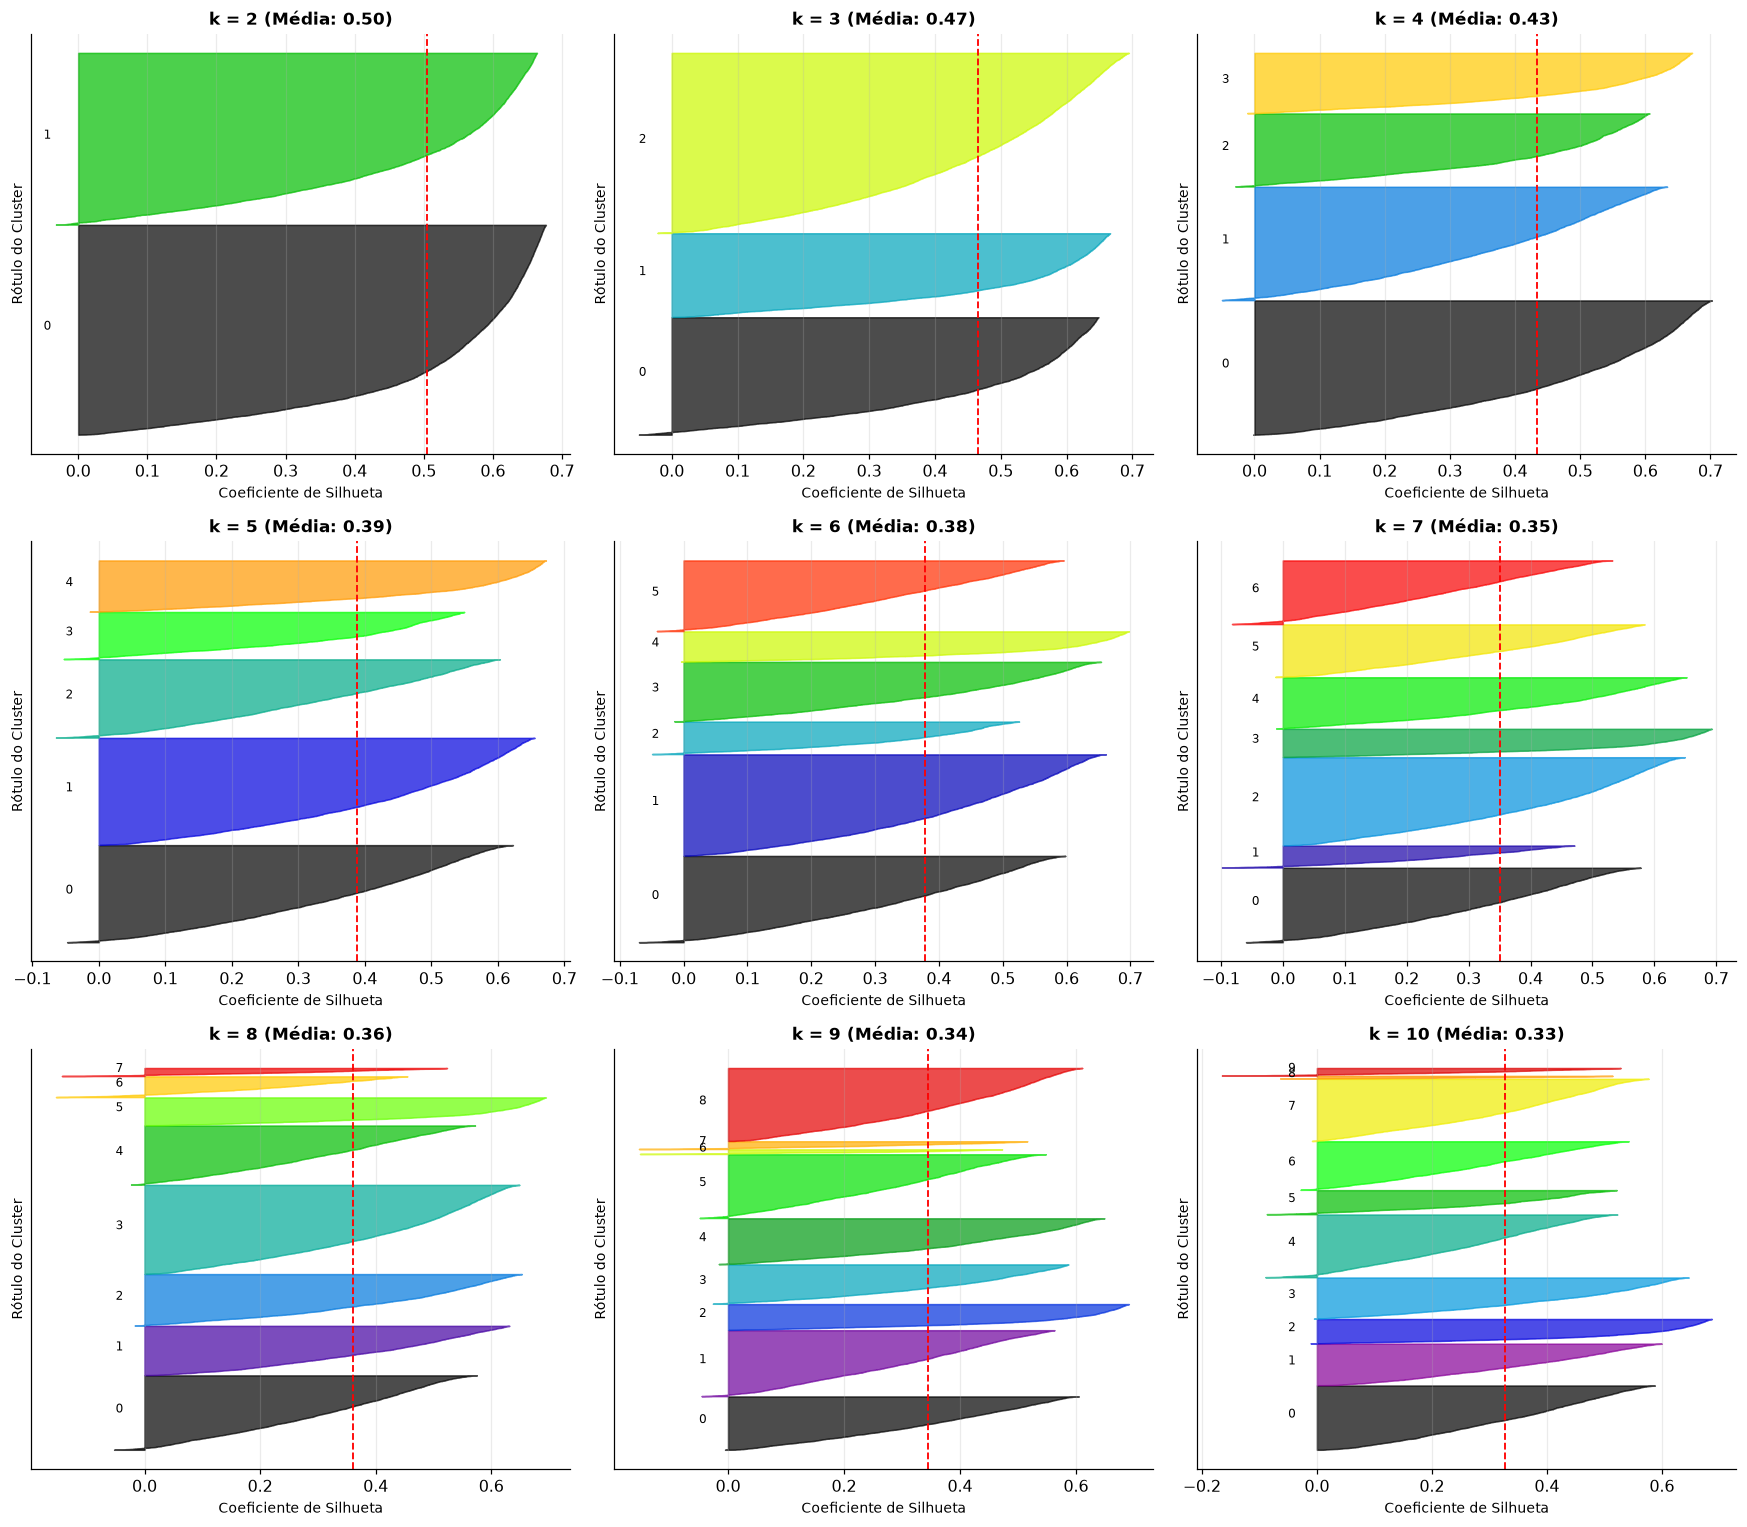

In [10]:
from sklearn.metrics import silhouette_samples
import matplotlib.cm as cm

# 9 valores (de 2 a 10) para preencher a grade 3x3
ks_to_test = range(2, 11)
fig, axes = plt.subplots(3, 3, figsize=(16, 14))
axes = axes.flatten()
for idx, n_clusters in enumerate(ks_to_test):
    ax = axes[idx]
    
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_scaled)
    
    silhouette_avg = silhouette_score(X_scaled, cluster_labels)
    sample_silhouette_values = silhouette_samples(X_scaled, cluster_labels)
    
    y_lower = 10
    for i in range(n_clusters):
        ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]
        ith_cluster_silhouette_values.sort()
        
        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i
        
        color = cm.nipy_spectral(float(i) / n_clusters)
        ax.fill_betweenx(np.arange(y_lower, y_upper),
                         0, ith_cluster_silhouette_values,
                         facecolor=color, edgecolor=color, alpha=0.7)
        
        ax.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i), fontsize=8)
        y_lower = y_upper + 10
    ax.set_title(f"k = {n_clusters} (Média: {silhouette_avg:.2f})", fontsize=11)
    ax.set_xlabel("Coeficiente de Silhueta", fontsize=9)
    ax.set_ylabel("Rótulo do Cluster", fontsize=9)
    
    # Linha vertical indicando o score médio
    ax.axvline(x=silhouette_avg, color="red", linestyle="--", linewidth=1.2)
    ax.set_yticks([])  # Limpa o eixo y
# Oculta subplots excedentes caso passe menos de 9 valores em ks_to_test
for j in range(len(ks_to_test), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

### **3.4 - Análise dos Resultados e Justificativa de K=4**

A partir das métricas e gráficos gerados nas etapas anteriores, realizamos as seguintes constatações metodológicas:

1. **Escolha do Algoritmo (K-Means vs. GMM vs. Hierárquico):** 
   O **K-Means** demonstrou superioridade empírica na clareza de separação dos dados, superando consistentemente a Clusterização Hierárquica e o GMM no *Silhouette Score*. Embora o GMM (probabilístico) mostrasse uma queda contínua no BIC, ele tende a criar subgrupos com variância muito fina. Como nosso objetivo no Estágio 1 é criar um conjunto discreto e bem delimitado de "Estados de Mortalidade" (como caixas bem definidas), o K-Means atende perfeitamente ao requisito de criar fronteiras nítidas [(Araújo, 2026)](https://arxiv.org/abs/2609.17268).

2. **O Veredito dos Diagramas de Silhueta ($K$):**
   * O $K=2$ apresenta o maior *Silhouette Score*, mas demograficamente representa apenas uma divisão binária (países de alta vs. baixa mortalidade), perdendo as nuances de transição essenciais para o Estágio 2.
   * Analisando os diagramas a partir de $K=3$, notamos que o **$K=4$** (Score = 0.43) apresenta um perfil extremamente robusto: todas as quatro "lâminas" de cluster ultrapassam a linha vermelha da média e, crucialmente, **quase não há presença de valores de silhueta negativos** (o que indicaria observações alocadas no cluster errado).
   * **Justificativa Demográfica para K=4:** Ao introduzir o quarto grupo (em vez da clássica divisão de 3 mundos), permitimos que o modelo capture um **estado de transição complexo**. Isso pode isolar, por exemplo, nações que já reduziram a mortalidade infantil, mas sofreram choques de mortalidade adulta (ex: impacto do HIV na África ou a crise de transição no leste europeu).

Portanto, fixaremos nosso modelo em **K-Means com 4 clusters**.

In [ ]:
# 1. Ajustando o modelo K-Means final com K=4
kmeans_final = KMeans(n_clusters=4, random_state=42, n_init=10)
df_hist['Estado_Mortalidade'] = kmeans_final.fit_predict(X_scaled)

# 2. Extraindo os Centróides (revertendo a padronização para interpretação demográfica)
centroides_padronizados = kmeans_final.cluster_centers_
centroides_reais = scaler.inverse_transform(centroides_padronizados)

# 3. Criando um DataFrame para visualização clara
df_centroides = pd.DataFrame(
    centroides_reais, 
    columns=features, 
    index=['Cluster 0', 'Cluster 1', 'Cluster 2', 'Cluster 3']
)

# 4. Ordenando os clusters pela Expectativa de Vida ao Nascer (do pior para o melhor cenário)
# O estado 0 será a pior mortalidade, e o estado 3 será a melhor.
df_centroides = df_centroides.sort_values(by='Exp_Vida_Nascer', ascending=True)

# Atualizamos os rótulos internos no DataFrame para refletir a nova ordem (0 a 3 ordinal)
mapeamento_clusters = {index_antigo: novo_valor for novo_valor, index_antigo in enumerate(df_centroides.index.str.replace('Cluster ', '').astype(int))}
df_hist['Estado_Mortalidade'] = df_hist['Estado_Mortalidade'].map(mapeamento_clusters)

# Atualiza o índice do DF de centróides para ficar ordenado 0, 1, 2, 3
df_centroides.index = [f'Estado {i}' for i in range(4)]

print("Centróides dos Estados de Mortalidade (K=4) - Ordenados de Pior a Melhor Saúde:")
display(df_centroides.round(1))

Centróides dos Estados de Mortalidade (K=4) - Ordenados de Pior a Melhor Saúde:


,Exp_Vida_Nascer,Mort_Infantil_Sub5,Mort_Adulta_15_60,Exp_Vida_15,Exp_Vida_65,Exp_Vida_80
Estado 0,42.0,261.5,438.1,44.3,10.9,4.8
Estado 1,57.1,121.9,295.2,51.2,12.4,5.4
Estado 2,69.8,35.0,169.8,57.6,14.4,6.2
Estado 3,78.1,9.1,95.9,63.9,18.2,8.4


### **3.5 - Perfilagem Demográfica dos Estados de Mortalidade (Conclusão do Estágio 1)**

Com os centróides extraídos e ordenados, podemos traçar o perfil epidemiológico que define cada "estado" da nossa modelagem. Os algoritmos capturaram perfeitamente as fases da Transição Demográfica global:

* **Estado 0 (Crise Aguda / Pré-Transição):** Expectativa de vida crítica (~42 anos). É marcado por uma mortalidade infantil extrema (261 mortes por 1000 nascidos vivos) e altíssima mortalidade adulta. Representa nações enfrentando extrema pobreza, ausência de saneamento básico, guerras ou picos severos de epidemias.
* **Estado 1 (Transição Inicial / Alta Mortalidade):** A expectativa de vida sobe para ~57 anos. Há vitórias no controle de doenças infecciosas, derrubando a mortalidade infantil pela metade (121/1000), mas ela e a mortalidade adulta (295/1000) ainda são grandes freios para a longevidade.
* **Estado 2 (Transição Avançada / Mortalidade Intermediária):** A expectativa de vida atinge a marca dos ~70 anos. Observa-se uma conquista massiva na sobrevivência infantil (cai para apenas 35/1000). O perfil de óbitos começa a sair da infância e migrar para as fases adulta e idosa.
* **Estado 3 (Pós-Transição / Baixa Mortalidade):** O estágio mais avançado (EV de ~78 anos). A mortalidade infantil torna-se um evento raro (9/1000) e a sobrevida em idades avançadas cresce sensivelmente (pessoas de 65 anos vivem em média mais 18.2 anos). A mortalidade está fortemente concentrada na velhice, com predominância de doenças crônico-degenerativas.

In [12]:
# 5. Salvando o dataset histórico classificado para a próxima etapa
caminho_salvamento = '../new_data/wpp2024_estados_mortalidade.csv'
df_hist.to_csv(caminho_salvamento, index=False)

print(f"✅ Dados com os Estados de Mortalidade salvos com sucesso em: {caminho_salvamento}")

✅ Dados com os Estados de Mortalidade salvos com sucesso em: ../new_data/wpp2024_estados_mortalidade.csv
